# Knee Osteoarthritis — shared baseline pipeline

**Purpose:** a small, reusable end-to-end starting point for the project. This notebook installs dependencies with **uv**, reads severity-labeled X-ray images, trains a small CNN for **one epoch**, and calculates validation accuracy and multiclass AUROC.

**Before running:** supply the path to your dataset in **Section 2**. This notebook assumes an `ImageFolder`-style dataset: either one folder of grade subfolders (`0/`, `1/`, etc.), **or** existing `train/`, `val/`, and `test/` folders that each contain grade subfolders.

> This is a **technical smoke test**, not a clinical diagnostic system. It will not produce meaningful performance until you train and validate properly. **Do not evaluate on the test set during development.** If multiple images belong to one patient, create patient-level splits outside this notebook rather than its illustrative image-level splitting option.

## 1. Install packages and check the environment

Run the next two cells once per fresh Colab runtime. They use `uv` to install missing packages **into this notebook's current Python environment**, so imports work immediately. On a local machine, you can instead manage dependencies with `uv sync` and select that environment as your Jupyter kernel.

In [1]:
!git clone https://github.com/michael-duer/medical-image-classification.git
%cd medical-image-classification


Cloning into 'medical-image-classification'...
remote: Enumerating objects: 8312, done.
remote: Total 8312 (delta 0), reused 0 (delta 0), pack-reused 8312 (from 2)
Receiving objects: 100% (8312/8312), 174.78 MiB | 42.84 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/content/medical-image-classification


In [2]:

from pathlib import Path
import sys

candidates = [
    Path("/content/medical-image-classification"),
    Path("/content/medical-image-classification/medical-image-classification")
]

PROJECT_ROOT = next(
    (p for p in candidates if (p / "data").is_dir()
     and (p / "src" / "metrics.py").is_file()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find dataset and metrics.py together.")

sys.path.insert(0, str(PROJECT_ROOT))

print("Project:", PROJECT_ROOT)
print("Dataset:", PROJECT_ROOT / "data")
print("Metrics module:", PROJECT_ROOT / "src" / "metrics.py")


Project: /content/medical-image-classification
Dataset: /content/medical-image-classification/data
Metrics module: /content/medical-image-classification/src/metrics.py


In [3]:
%pip -q install uv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.9/17.9 MB 93.0 MB/s eta 0:00:00


In [4]:
import importlib.util
import subprocess
import sys

required = {
    "torch": "torch",
    "torchvision": "torchvision",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "PIL": "pillow",
    "tqdm": "tqdm",
}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run(["uv", "pip", "install", "--python", sys.executable, *missing], check=True)
else:
    print("All baseline dependencies are already installed.")
print("Notebook Python:", sys.executable)
print("If an import fails after installation, restart the runtime and rerun.")

All baseline dependencies are already installed.
Notebook Python: /usr/bin/python3
If an import fails after installation, restart the runtime and rerun.


In [5]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## 2. Configure data paths

**Colab:** mount your own Google Drive (a shared folder may need to be added as a shortcut to *My Drive*). **Local:** skip the mount cell and provide a local path. If you prefer, copy images from Drive to Colab's `/content/` storage to improve loading speed. Do not commit medical images to GitHub.

In [6]:
#On Colab only, uncomment and run:
#from google.colab import drive
#drive.mount('/content/drive')

# EDIT THIS PATH. Examples:
#'/content/drive/MyDrive/Knee_OA_Project/dataset'
#'/content/knee_oa_data'
#'./data/knee_oa'
#DATA_DIR = Path("")

# Optional: point to a Drive folder so checkpoints survive Colab disconnects.
#OUTPUT_DIR = Path('/content/drive/MyDrive/Knee_OA_Project/checkpoints')

# For testing the pipeline locally on a small subset use:
DATA_DIR = Path('/content/medical-image-classification/data')
OUTPUT_DIR = Path('/content/medical-image-classification/output')

# Input layout:
# A) dataset/0/*.png, dataset/1/*.png, ...
# B) dataset/train/0/*.png, dataset/val/0/*.png, dataset/test/0/*.png, ...
# Grade folder names can also be words such as Healthy, Doubtful, etc.
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0   # portable default; try 2 in Colab after confirming it runs
EPOCHS = 1        # intentionally a smoke test
LR = 1e-3

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Set DATA_DIR to your actual dataset folder first: {DATA_DIR}")
print('Dataset path:', DATA_DIR.resolve())

Dataset path: /content/medical-image-classification/data


## Remove macOS metadata files (._*) from the dataset

In [7]:
from pathlib import Path

data_dir = Path("/content/medical-image-classification/data")

mac_files = list(data_dir.rglob("._*"))

print("Mac metadata files found:", len(mac_files))

for file in mac_files:
    file.unlink()

print("Removed Mac metadata files.")

Mac metadata files found: 0
Removed Mac metadata files.


## 3. Load and inspect data

The same label mapping and normalization will be used by every model. For fair comparison, **save and reuse the same split manifest** before individual experiments. If your data already comes with splits, this notebook respects them. If not, the fallback stratified image-level split below is for smoke-testing only and must be replaced when patients have multiple images.

The transform converts X-rays to **3-channel RGB** so this data pipeline also works with standard ImageNet-pretrained CNNs later.

In [20]:
from torchvision.datasets.folder import default_loader

# Normalization matches common ImageNet-pretrained ResNet/EfficientNet weights.
# Keep these choices the same in all experiments.
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


from src.class_imbalance import (
    get_transforms,
    create_weighted_sampler
)

train_transform = get_transforms(
    image_size=IMAGE_SIZE,
    train=True,
    mean=MEAN,
    std=STD
)

eval_transform = get_transforms(
    image_size=IMAGE_SIZE,
    train=False,
    mean=MEAN,
    std=STD
)


class ImageSubset(Dataset):
    """ImageFolder-compatible subset that stores explicit (path, label) entries."""
    def __init__(self, samples, transform):
        self.samples = [(str(p), int(y)) for p, y in samples]
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = default_loader(path)  # RGB
        return self.transform(img), label

existing_train = DATA_DIR / 'train'
existing_val = DATA_DIR / 'val'
existing_test = DATA_DIR / 'test'

if existing_train.is_dir() and existing_val.is_dir() and existing_test.is_dir():
    print('Using supplied train/val/test folders.')
    train_source = datasets.ImageFolder(existing_train)
    val_source = datasets.ImageFolder(existing_val)
    test_source = datasets.ImageFolder(existing_test)
    class_names = train_source.classes
    assert val_source.class_to_idx == train_source.class_to_idx == test_source.class_to_idx,         'Class folders do not match across splits.'
    split_samples = {
        'train': train_source.samples,
        'val': val_source.samples,
        'test': test_source.samples,
    }
else:
    print('No complete train/val/test layout found: creating illustrative image-level splits.')
    whole = datasets.ImageFolder(DATA_DIR)
    class_names = whole.classes
    paths = np.array([path for path, _ in whole.samples])
    labels = np.array([label for _, label in whole.samples])
    # 70% train / 15% val / 15% test, stratified by grade.
    ix = np.arange(len(paths))
    train_ix, remainder_ix = train_test_split(
        ix, test_size=0.30, random_state=SEED, stratify=labels)
    val_ix, test_ix = train_test_split(
        remainder_ix, test_size=0.50, random_state=SEED,
        stratify=labels[remainder_ix])
    split_samples = {
        'train': [(paths[i], labels[i]) for i in train_ix],
        'val': [(paths[i], labels[i]) for i in val_ix],
        'test': [(paths[i], labels[i]) for i in test_ix],
    }
    print('WARNING: image-level splitting is inappropriate if patients have multiple images.')

num_classes = len(class_names)
assert num_classes >= 2, 'At least two grade folders are required.'
print('Class mapping:', {name: i for i, name in enumerate(class_names)})
for split, entries in split_samples.items():
    print(f'{split}: {len(entries)} images')

# For shared reproducibility: export the same manifest to all members.
manifest = pd.DataFrame(
    [(split, str(path), int(label)) for split, entries in split_samples.items()
     for path, label in entries],
    columns=['split', 'path', 'label']
)
# Save to a shared persistent location AFTER confirming splits are appropriate.
# manifest.to_csv('/content/drive/MyDrive/Knee_OA_Project/split_manifest.csv', index=False)

datasets_by_split = {
    split: ImageSubset(
        samples,
        train_transform if split == "train" else eval_transform
    )
    for split, samples in split_samples.items()
}

train_sampler = create_weighted_sampler(
    split_samples["train"],
    num_classes
)

loaders = {
    "train": DataLoader(
        datasets_by_split["train"],
        batch_size=BATCH_SIZE,
        sampler=train_sampler,
        num_workers=NUM_WORKERS
    ),
    "val": DataLoader(
        datasets_by_split["val"],
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS
    ),
    "test": DataLoader(
        datasets_by_split["test"],
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS
    )
}

images, labels = next(iter(loaders["train"]))
print("One batch:", images.shape)


Using supplied train/val/test folders.
Class mapping: {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4}
train: 5778 images
val: 826 images
test: 1656 images
Training class counts: [2286 1046 1516  757  173]
Class sampling weights: [0.00043745 0.00095602 0.00065963 0.001321   0.00578035]
One batch: torch.Size([16, 3, 224, 224])


## Class Distribution Before and After Weighted Sampling

In [21]:

from collections import Counter

original_labels = [
    label for path, label in split_samples["train"]
]

sampled_labels = []
for _, labels in loaders["train"]:
    sampled_labels.extend(labels.tolist())

print("Original distribution:")
print(Counter(original_labels))

print("\nSampled distribution (one epoch):")
print(Counter(sampled_labels))


Original distribution:
Counter({0: 2286, 2: 1516, 1: 1046, 3: 757, 4: 173})

Sampled distribution (one epoch):
Counter({0: 1205, 1: 1156, 3: 1145, 2: 1140, 4: 1132})


## Sample Image Visualization and Dataset Class Distribution

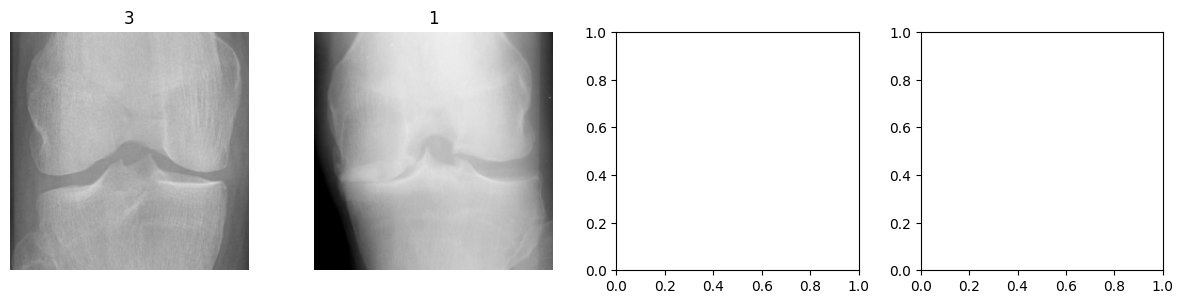

label     0     1     2    3    4
split                            
test    639   296   447  223   51
train  2286  1046  1516  757  173
val     328   153   212  106   27


In [22]:
# Show several *unnormalized* examples; no training required.
fig, axes = plt.subplots(1, min(4, len(images)), figsize=(12, 3))
axes = np.atleast_1d(axes)
for ax, image, label in zip(axes, images, labels):
    display_image = image.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
    ax.imshow(display_image.clip(0, 1))
    ax.set_title(class_names[int(label)])
    ax.axis('off')
plt.tight_layout()
plt.show()

print(pd.crosstab(manifest['split'], manifest['label']).rename(
    columns={i: name for i, name in enumerate(class_names)}))

## Check the class distribution before and after sampling

KL Grade | Original | After Sampling
-------------------------------------
KL0      |  2286    |  1155
KL1      |  1046    |  1192
KL2      |  1516    |  1108
KL3      |   757    |  1154
KL4      |   173    |  1169


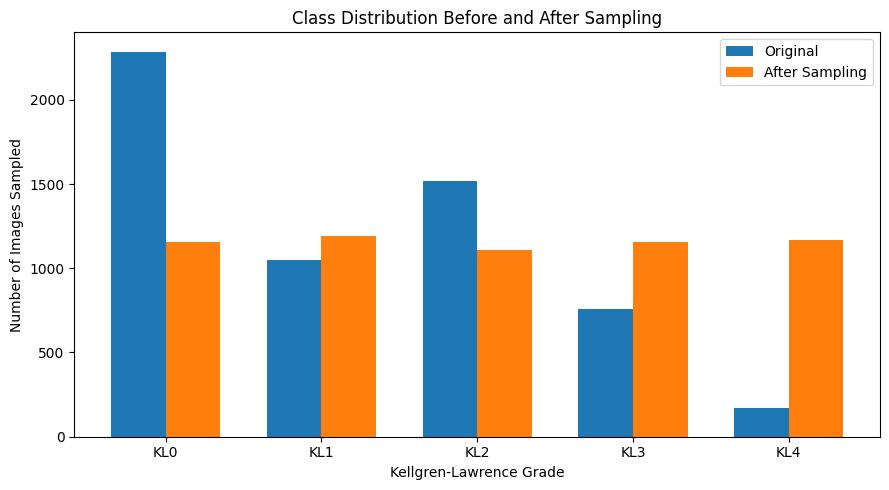

In [30]:

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Original training distribution
original_labels = [
    label for path, label in split_samples["train"]
]

original_counts = Counter(original_labels)

# Distribution after weighted sampling (one epoch)
sampled_labels = []

for _, labels in loaders["train"]:
    sampled_labels.extend(labels.numpy().tolist())

sampled_counts = Counter(sampled_labels)

# Display comparison
print("KL Grade | Original | After Sampling")
print("-------------------------------------")

for grade in range(5):
    print(
        f"KL{grade}      | "
        f"{original_counts[grade]:5d}    | "
        f"{sampled_counts[grade]:5d}"
    )

# Plot
grades = np.arange(5)
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    grades - width/2,
    [original_counts[i] for i in grades],
    width,
    label="Original"
)

plt.bar(
    grades + width/2,
    [sampled_counts[i] for i in grades],
    width,
    label="After Sampling"
)

plt.xticks(grades, [f"KL{i}" for i in grades])
plt.xlabel("Kellgren-Lawrence Grade")
plt.ylabel("Number of Images Sampled")
plt.title("Class Distribution Before and After Sampling")
plt.legend()
plt.tight_layout()
plt.show()


## 4. Minimal custom CNN

This deliberately simple baseline is only for validating the common pipeline. It will later be replaced or extended with an improved version. Its final layer outputs one **logit per grade**; no softmax is used before cross-entropy loss.

In [23]:
class TinyCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Linear(64, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))

model = TinyCNN(num_classes).to(DEVICE)
with torch.no_grad():
    output = model(images[:2].to(DEVICE))
print('Output shape:', tuple(output.shape))
assert output.shape == (min(2, len(images)), num_classes)

Output shape: (2, 5)


## 5. Reusable training + validation loops

For the shared smoke test, **one epoch is sufficient**.

In [24]:
def run_epoch(model, loader, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)
    criterion = nn.CrossEntropyLoss()
    total_loss, correct, count = 0.0, 0, 0
    for x, y in tqdm(loader, leave=False, desc='train' if is_training else 'validate'):
        x, y = x.to(DEVICE), y.to(DEVICE)
        if is_training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(is_training):
            logits = model(x)
            loss = criterion(logits, y)
            if is_training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        count += y.size(0)
    return {'loss': total_loss / count, 'accuracy': correct / count}

optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = []
for epoch in range(3):
    train_stats = run_epoch(model, loaders['train'], optimizer)
    val_stats = run_epoch(model, loaders['val'])
    history.append({'epoch': epoch + 1,
                    'train_loss': train_stats['loss'],
                    'train_accuracy': train_stats['accuracy'],
                    'val_loss': val_stats['loss'],
                    'val_accuracy': val_stats['accuracy']})
    print(history[-1])
pd.DataFrame(history)

train:   0%|          | 0/362 [00:00<?, ?it/s]

validate:   0%|          | 0/52 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.6099339822206005, 'train_accuracy': 0.2049151955694012, 'val_loss': 1.597396712326253, 'val_accuracy': 0.39588377723970947}


train:   0%|          | 0/362 [00:00<?, ?it/s]

validate:   0%|          | 0/52 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 1.6081451866279304, 'train_accuracy': 0.2151263412945656, 'val_loss': 1.6140309857975772, 'val_accuracy': 0.1585956416464891}


train:   0%|          | 0/362 [00:00<?, ?it/s]

validate:   0%|          | 0/52 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 1.60803575650265, 'train_accuracy': 0.2201453790238837, 'val_loss': 1.6302895606574366, 'val_accuracy': 0.12832929782082325}


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,1.609934,0.204915,1.597397,0.395884
1,2,1.608145,0.215126,1.614031,0.158596
2,3,1.608036,0.220145,1.630290,0.128329


## 6. Validation predictions and metrics

For multiclass AUROC, use softmax probabilities and specify **one-vs-rest, macro average**. If validation contains no samples for a class, AUROC may be undefined; the function reports that rather than inventing a score.

**Do not evaluate the test split yet.** The shared team should agree on the final evaluation protocol first.

In [25]:
@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    actual, probs = [], []
    for x, y in loader:
        logits = model(x.to(DEVICE))
        actual.append(y.numpy())
        probs.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(actual), np.concatenate(probs)

def summarize_metrics(y_true, probabilities, class_names):
    predictions = probabilities.argmax(axis=1)
    results = {'accuracy': accuracy_score(y_true, predictions)}
    present = np.unique(y_true)
    if len(class_names) == 2 and len(present) == 2:
        results['auroc'] = roc_auc_score(y_true, probabilities[:, 1])
    elif len(present) == len(class_names):
        results['auroc'] = roc_auc_score(
            y_true, probabilities, labels=np.arange(len(class_names)),
            multi_class='ovr', average='macro')
    else:
        results['auroc'] = float('nan')
        print('AUROC undefined: not all classes appear in this validation split.')
    return results, confusion_matrix(y_true, predictions,
                                      labels=np.arange(len(class_names)))

y_val, val_prob = get_predictions(model, loaders['val'])
metrics, cm = summarize_metrics(y_val, val_prob, class_names)
print('Validation metrics:', metrics)
print('Confusion matrix (rows=true, cols=predicted):')
display(pd.DataFrame(cm, index=class_names, columns=class_names))

Validation metrics: {'accuracy': 0.12832929782082325, 'auroc': np.float64(0.5155220604610006)}
Confusion matrix (rows=true, cols=predicted):


,0,1,2,3,4
0,0,0,0,327,1
1,0,0,0,153,0
2,0,0,0,212,0
3,0,0,0,106,0
4,0,0,0,27,0


## Import, Reload, and Verify the Metrics Module

In [26]:
import sys
import importlib
import inspect

# Make sure Colab finds your project
sys.path.insert(0, "/content/medical-image-classification")

# Reload the updated metrics module
import src.metrics
importlib.reload(src.metrics)

# Import the updated function
from src.metrics import evaluate_predictions

# Check which file and function Colab is using
print("File:", inspect.getfile(evaluate_predictions))
print("Function:", inspect.signature(evaluate_predictions))

File: /content/medical-image-classification/src/metrics.py
Function: (y_true, y_prob=None, y_pred=None, *, model_name='cnn', output_dir='metrics_output', class_names=None, logits=None, show_plots=True, save_plots=False)


## Verification of Metrics Module and Plotting Configuration

In [27]:
import importlib
import inspect
import src.metrics

importlib.reload(src.metrics)

# Always use the function directly from the reloaded module
evaluate_predictions = src.metrics.evaluate_predictions

print("1. File:", inspect.getfile(evaluate_predictions))
print("2. Signature:", inspect.signature(evaluate_predictions))
print("3. Backend:", src.metrics.plt.get_backend())

source = inspect.getsource(evaluate_predictions)

print("4. Contains display(fig):", "display(fig)" in source)
print("5. Contains plt.show():", "plt.show()" in source)
print("6. Contains if show_plots:", "if show_plots:" in source)

1. File: /content/medical-image-classification/src/metrics.py
2. Signature: (y_true, y_prob=None, y_pred=None, *, model_name='cnn', output_dir='metrics_output', class_names=None, logits=None, show_plots=True, save_plots=False)
3. Backend: module://matplotlib_inline.backend_inline
4. Contains display(fig): False
5. Contains plt.show(): True
6. Contains if show_plots: True


## **7**. Detailed CNN evaluation

Current backend: module://matplotlib_inline.backend_inline
True labels: (1656,)
Predicted probabilities: (1656, 5)


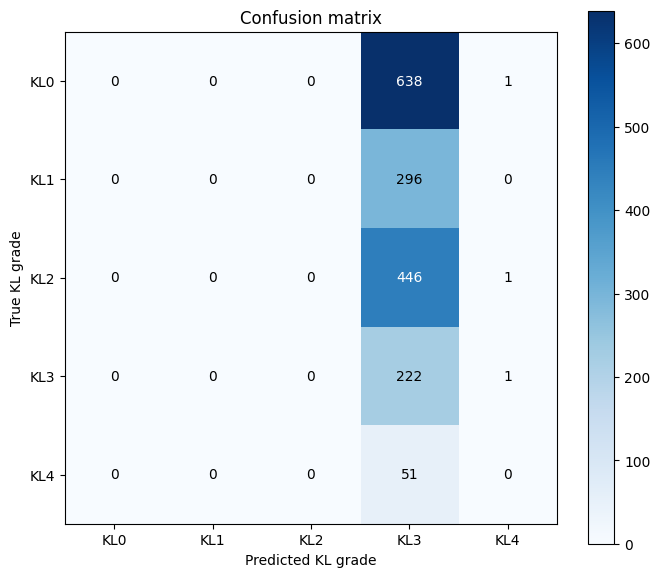

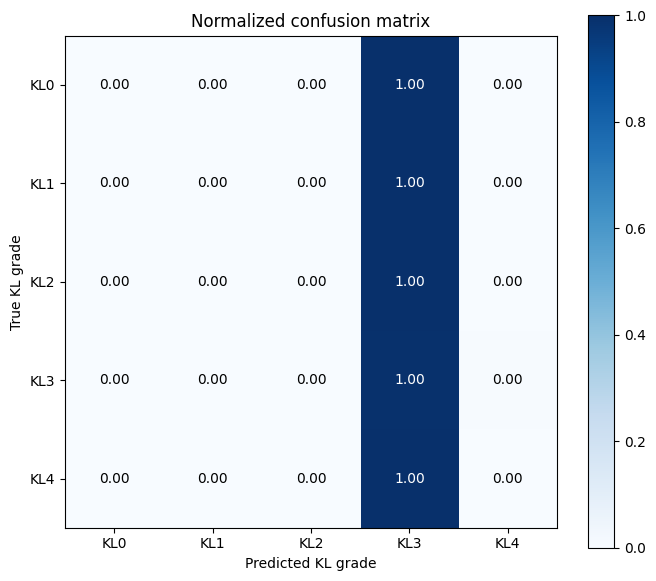

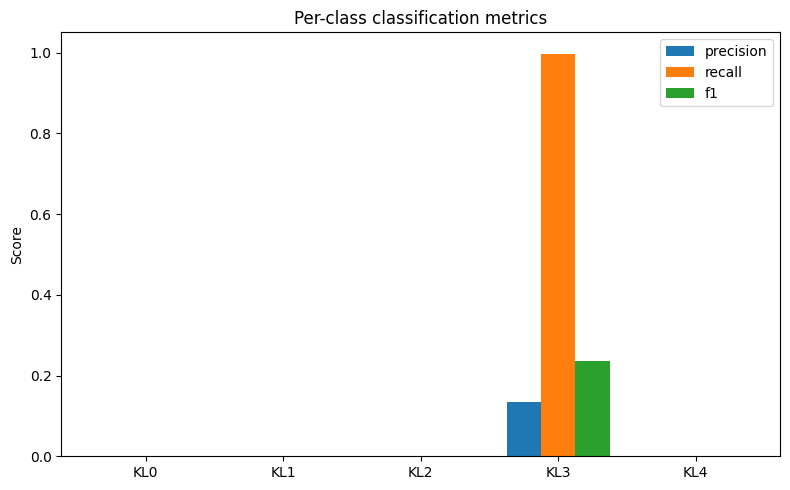

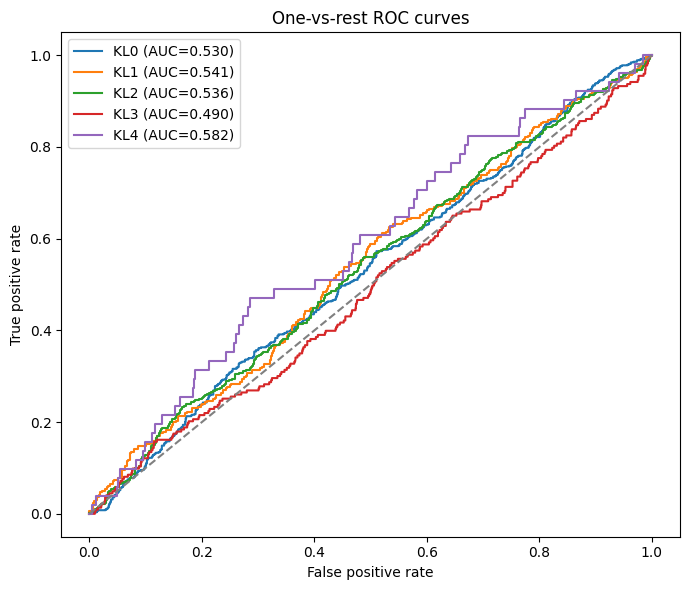

{'model_name': 'TinyCNN', 'n_samples': 1656, 'accuracy': 0.13405797101449277, 'balanced_accuracy': 0.19910313901345292, 'macro_f1': 0.04733475479744136, 'weighted_f1': 0.03187092487871203, 'quadratic_weighted_kappa': 0.0003391329775925822, 'mae': 1.817632850241546, 'macro_auroc_ovr': 0.5358273922993089}


In [28]:
import matplotlib
import matplotlib.pyplot as plt

plt.switch_backend("module://matplotlib_inline.backend_inline")

print("Current backend:", matplotlib.get_backend())

# Generate predictions
y_test, test_prob = get_predictions(model, loaders["test"])

print("True labels:", y_test.shape)
print("Predicted probabilities:", test_prob.shape)

import src.metrics

importlib.reload(src.metrics)
from src.metrics import evaluate_predictions

# Evaluate CNN performance
results = evaluate_predictions(
    y_true=y_test,
    y_prob=test_prob,
    model_name="TinyCNN",
    show_plots=True,
    save_plots=False
)

print(results)

## **8**. Training and validation plots

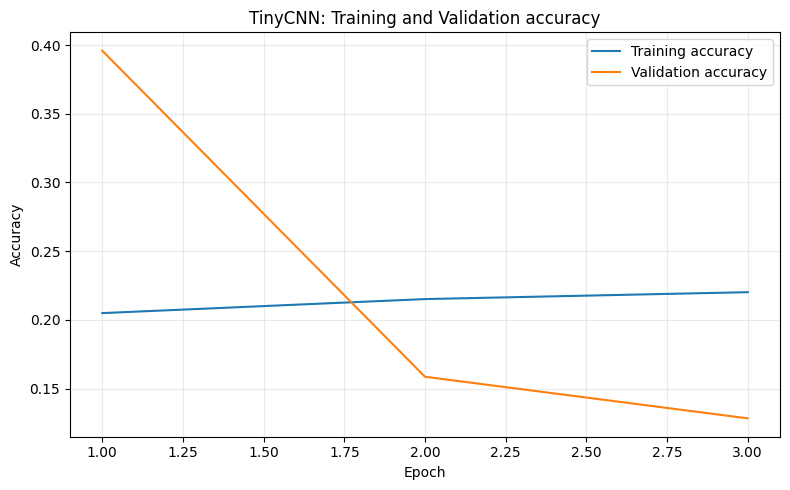

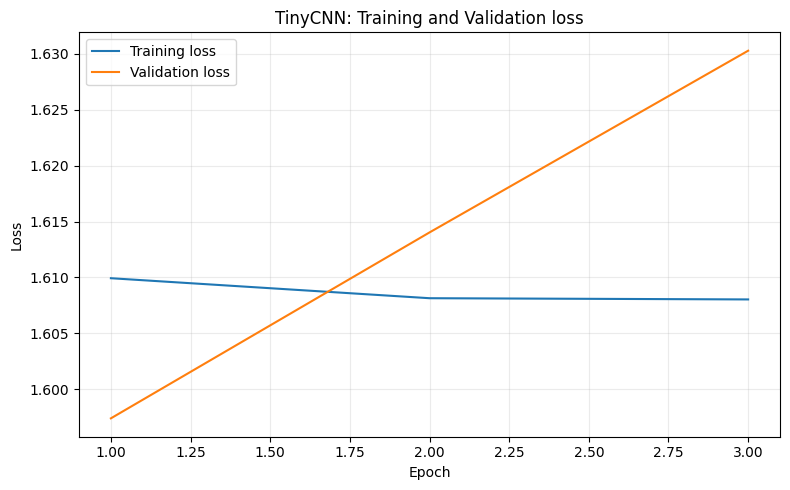

{}

In [29]:
from src.metrics import plot_training_history

plot_training_history(
    history,
    output_dir=OUTPUT_DIR / "metrics",
    model_name="TinyCNN",
    show_plots = True,
    save_plots = False
)

## 9. Optional: save a checkpoint

In Colab, **first mount Drive and set `OUTPUT_DIR` to your own writable Drive path**. Saving directly under `/content/` is temporary. Store large weights in Drive, not GitHub. Experiment settings belong alongside checkpoints.

In [ ]:
SAVE_CHECKPOINT = False  # Change to True once OUTPUT_DIR is configured.
if SAVE_CHECKPOINT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    checkpoint_file = OUTPUT_DIR / 'tiny_cnn_smoke_test.pt'
    torch.save({
        'model_state_dict': model.state_dict(),
        'class_names': class_names,
        'image_size': IMAGE_SIZE,
        'normalization_mean': MEAN,
        'normalization_std': STD,
        'seed': SEED,
        'history': history,
    }, checkpoint_file)
    print('Saved:', checkpoint_file)
else:
    print('Checkpoint not saved; set SAVE_CHECKPOINT=True to enable.')